# Taxi (big classification dataset)

UCI Taxi Service Trajectory (Porto, ECML PKDD 2015), ~1.7M trips. Target `CALL_TYPE`
(A = central, B = taxi stand, C = street), metric log-loss. Step 4: steps 1-3 with logistic
regression.

Features: hour, weekday, trip duration, start/end coordinates, distance. `ORIGIN_CALL` /
`ORIGIN_STAND` are left out because they give away the label. The notebook uses a random
subset of 20,000 trips (`RUN_FULL = False`).

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve
from lab.sampler import linear_sizes, log_sizes, sample_training_sets

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

In [2]:
DATASET = "taxi"
TASK = "classification"
KINDS = ["logistic", "quadratic_logistic"]
N_REPEATS = 5

# False: random 20k-trip subset, True: all ~1.7M trips (slow)
RUN_FULL = False
MAX_ROWS = None if RUN_FULL else 20_000
RUN_NAME = f"{DATASET}_{'full' if RUN_FULL else 'small'}"
CV_MAX_ROWS = 100_000   # CV on a random subset (speed)

## Data

In [3]:
from lab.data_taxi import load_taxi, month_groups, split_taxi

X, y, time = load_taxi(max_rows=MAX_ROWS)
print(X.shape, "trips from", time.min().date(), "to", time.max().date())
display(X.head())
print("class proportions:")
print(y.value_counts(normalize=True))

(20000, 8) trips from 2013-07-01 to 2014-07-01


,hour,weekday,n_points,start_lon,start_lat,end_lon,end_lat,distance_km
0,22,4,44,-8.634,41.17,-8.61,41.15,2.91
1,4,1,30,-8.594,41.17,-8.562,41.15,3.215
2,23,3,104,-8.628,41.16,-8.72,41.27,14.4
3,18,2,39,-8.649,41.17,-8.661,41.16,1.052
4,3,5,30,-8.605,41.16,-8.612,41.15,1.576


class proportions:
CALL_TYPE
B   0.4829
C    0.305
A    0.212
Name: proportion, dtype: float64


## Train / validation split
Temporal: trips before a cutoff date for training, the last ~20% of days for validation. This
is the realistic setting (train on the past), keeps trips of the same day (weather, events) on
one side, and the class mix drifts a bit over the year (B ~51% → ~47%, C ~28% → ~33%).

The learning-curve samples are still drawn at random from the training part.

In [4]:
X_train, X_val, y_train, y_val = split_taxi(X, y, time)
print(f"training part: {len(X_train):,} rows, validation: {len(X_val):,} rows")
display(pd.DataFrame({"train": y_train.value_counts(normalize=True),
                      "validation": y_val.value_counts(normalize=True)}).round(3))

training: trips before 2014-04-23, validation: from 2014-04-23 on
training part: 15,983 rows, validation: 4,017 rows


,train,validation
CALL_TYPE,,
B,0.489,0.458
C,0.299,0.33
A,0.212,0.212


In [5]:
# number of features after one-hot / squaring
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

            logistic: 37 features
  quadratic_logistic: 58 features


Multinomial logistic regression has one weight per feature and class, so about 3x the
feature count in parameters.

## Step 4: learning curves

In [6]:
# log-spaced sizes up to the whole training part
sizes = log_sizes(10, len(X_train), 15)
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK)
curve.to_csv(RESULTS_DIR / f"{RUN_NAME}_curve.csv", index=False)

stats = summarize(curve)
display(stats)
print(f"total fitting time: {curve['fit_seconds'].sum():.0f} s")

[10, 17, 29, 49, 82, 139, 236, 400, 677, 1147, 1942, 3290, 5572, 9437, 15983]
size       10


size       17


size       29


size       49


size       82


...

size     5572


size     9437


size    15983


model   size train_score                                \
                                     mean       std    median       q25   
0             logistic     10   0.0002844 7.228e-05 0.0002922 0.0002626   
1             logistic     17   0.0002602 2.823e-05 0.0002503  0.000243   
2             logistic     29   0.0002697 0.0001154 0.0002519 0.0002169   
3             logistic     49   0.0002634 0.0001296 0.0002519 0.0001507   
4             logistic     82      0.2877    0.2236    0.3065    0.1293   
5             logistic    139      0.5931    0.1205    0.6315    0.4963   
6             logistic    236      0.8014   0.04151    0.7986    0.7896   
7             logistic    400      0.8734   0.02997    0.8829    0.8428   
8             logistic    677      0.9222   0.02317    0.9146    0.9019   
9             logistic   1147      0.9488    0.0088    0.9485    0.9464   
10            logistic   1942      0.9581   0.00342    0.9559    0.9557   
11            logistic   3290      0.9626  0.007237    0.9616    0.9588   
12            logistic   5572      0.9724  0.004234    0.9718    0.9687   
13            logistic   9437      0.9754  0.002276    0.9759     0.974   
14            logistic  15983      0.9769         0    0.9769    0.9769   
15  quadratic_logistic     10   0.0001986 3.793e-05 0.0002174 0.0001954   
16  quadratic_logistic     17   0.0001602 3.559e-05 0.0001447 0.0001369   
17  quadratic_logistic     29   0.0002194 7.833e-05 0.0002207 0.0001565   
18  quadratic_logistic     49    0.000252 4.854e-05 0.0002354 0.0002259   
19  quadratic_logistic     82     0.00446  0.009422 0.0002407 0.0001705   
20  quadratic_logistic    139      0.4385    0.1346    0.4396    0.3259   
21  quadratic_logistic    236       0.702   0.05773    0.6974    0.6686   
22  quadratic_logistic    400      0.8071   0.02576    0.7917    0.7885   
23  quadratic_logistic    677      0.8768   0.02368    0.8697    0.8638   
24  quadratic_logistic   1147      0.9202  0.009275    0.9202    0.9166   
25  quadratic_logistic   1942       0.932  0.009696    0.9344     0.931   
26  quadratic_logistic   3290       0.942  0.007339    0.9408     0.937   
27  quadratic_logistic   5572      0.9536  0.005538    0.9549    0.9494   
28  quadratic_logistic   9437      0.9599  0.001421    0.9606    0.9589   
29  quadratic_logistic  15983      0.9609         0    0.9609    0.9609   

             val_score                                 
         q75      mean       std median    q25    q75  
0  0.0002994     4.837    0.9135  4.306  4.184  5.432  
1  0.0002702     7.063     1.264   6.47  6.302  8.344  
2  0.0002945     9.956     4.204   9.65  8.376  9.845  
3  0.0003926     17.72     3.314  17.96  17.11  19.51  
4     0.4851     13.27     6.939  13.55  8.036  19.79  
5     0.6422     2.999    0.7162  3.322  2.361  3.443  
6     0.8036     1.543    0.1977  1.512  1.411  1.574  
7     0.8979     1.219     0.072  1.193  1.186  1.273  
8     0.9452     1.058   0.02415   1.06   1.05  1.067  
9     0.9561     1.021  0.007723  1.019  1.015  1.028  
10    0.9605     0.998  0.004123 0.9967 0.9963      1  
11    0.9693    0.9935  0.002781 0.9939 0.9914 0.9955  
12    0.9755    0.9878  0.001317 0.9877 0.9869 0.9886  
13    0.9773    0.9846 0.0004067 0.9845 0.9843  0.985  
14    0.9769    0.9827         0 0.9827 0.9827 0.9827  
15  0.000221     7.947     1.555  8.774  7.672  8.953  
16 0.0001669     11.53     2.711  11.53  11.32  13.16  
17 0.0002279     12.38      4.01  11.66  11.62  13.81  
18 0.0002381     17.19     3.092  17.82   15.6   19.2  
19 0.0004243     20.61     1.135  20.73  19.59  21.52  
20    0.5148     6.909     2.395  6.581  5.729  7.217  
21    0.7117     3.017    0.8919  3.172   2.55  3.263  
22    0.8298     1.878    0.2129  1.789  1.725  2.015  
23    0.8823     1.139   0.08115  1.117  1.082  1.139  
24    0.9223     1.063   0.04219  1.046  1.044   1.06  
25    0.9345     1.012  0.007795  1.011  1.008  1.015  
26    0.9468    0.9959  0.006571 0.9937 0.9913 0

total fitting time: 15 s


baseline validation log-loss: 1.0552


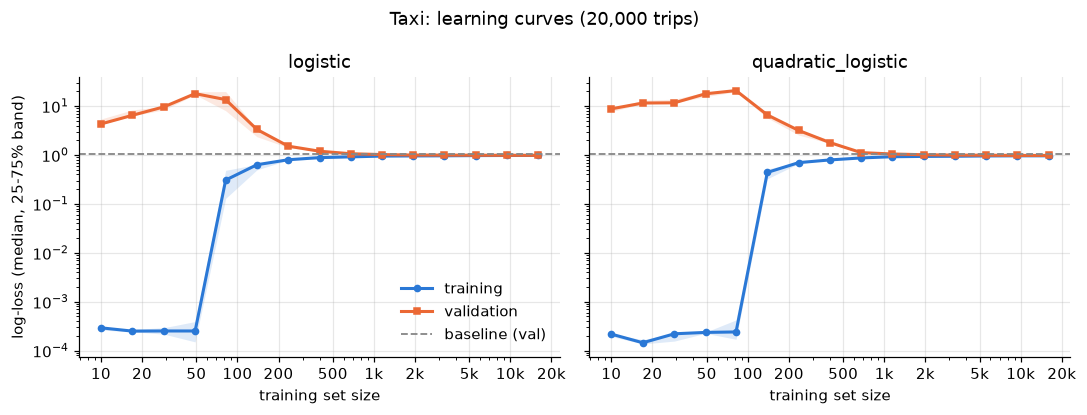

In [7]:
# baseline: predict the training class proportions
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation log-loss: {baseline:.4f}")

fig = plot_learning_curve(curve, "log-loss", f"Taxi: learning curves ({len(X):,} trips)",
                          baseline=baseline, log_x=True, log_y=True,
                          path=FIGURES_DIR / f"{RUN_NAME}_learning_curves.png")

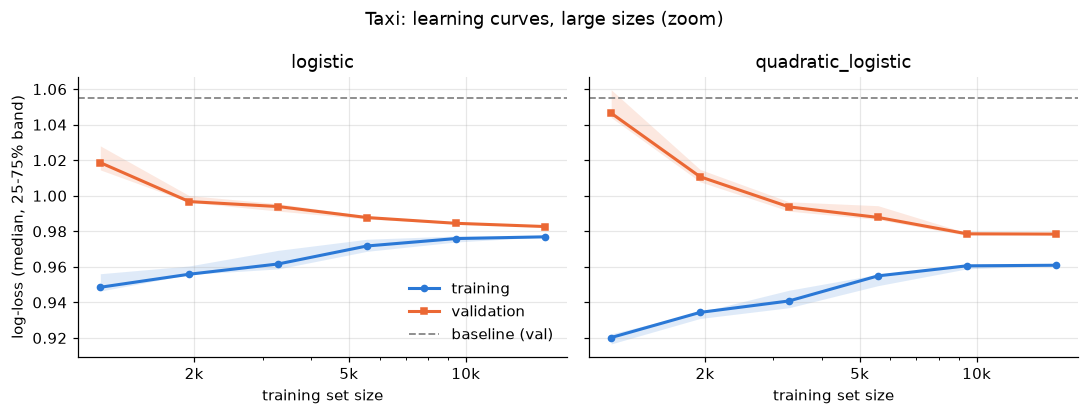

In [8]:
# zoom on the large sizes
large = curve[curve["size"] >= 1000]
fig = plot_learning_curve(large, "log-loss", "Taxi: learning curves, large sizes (zoom)",
                          baseline=baseline, log_x=True,
                          path=FIGURES_DIR / f"{RUN_NAME}_learning_curves_zoom.png")

### Explanation

**Small samples.** With few trips compared to the number of parameters the classes are
separable, the unregularized weights grow without limit and the predicted probabilities are
almost 0 or 1. The training log-loss is ~0 and the validation log-loss is far above the
baseline, because a confident mistake costs `-log(p)`. It is worst just before the samples
stop being separable (~80 trips for logistic, ~140 for quadratic); then the training loss
jumps up and the validation loss drops.

**Large samples.** Both curves meet slightly below the baseline (~0.98 vs 1.055). The gap is
gone but the level stays high: time and place of a trip say little about how it was ordered.
That is bias, so more data would not help.

**Quadratic.** Needs more data before it stops overfitting, but ends slightly lower
(validation 0.978 vs 0.983).

## Step 3: cross-validation
5-fold CV on the training part, holding out whole months (`GroupKFold` by month) to match the
temporal split.

In [9]:
from sklearn.model_selection import GroupKFold

cv = cross_validate_models(X_train, y_train, KINDS, TASK, folds=GroupKFold(n_splits=5),
                           groups=month_groups(time.loc[X_train.index]), max_rows=CV_MAX_ROWS)
cv.to_csv(RESULTS_DIR / f"{RUN_NAME}_cv.csv", index=False)

largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,logistic,0.9828,0.01073,15983,0.9769,0.9827
1,quadratic_logistic,0.9717,0.01017,15983,0.9609,0.9784


CV chooses: quadratic_logistic


### CV vs. learning curves

CV picks the **quadratic** model (0.972 vs 0.983), same as the validation curves. Training,
validation and CV errors are all close: with thousands of trips these models cannot overfit.
The CV error is a bit lower than the validation error because the validation months lie in
the future and the class mix drifts. Very different from automobile, where the three errors
differ by orders of magnitude.